[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tayalmanan28/MuJoCo-Tutorial/blob/main/tutorial/05_contact.ipynb)

# Tutorial 5: Contacts & Collisions

Understand how MuJoCo handles contacts, read contact forces, and configure contact parameters.

In [1]:
!pip install -q mujoco mediapy matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.2/30.2 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 55.1 MB/s eta 0:00:00


In [2]:
import os
os.environ['MUJOCO_GL'] = 'egl'
import mujoco
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media

## Contact Detection

MuJoCo detects contacts automatically between all geom pairs.
Active contacts are stored in `data.contact[:data.ncon]`.

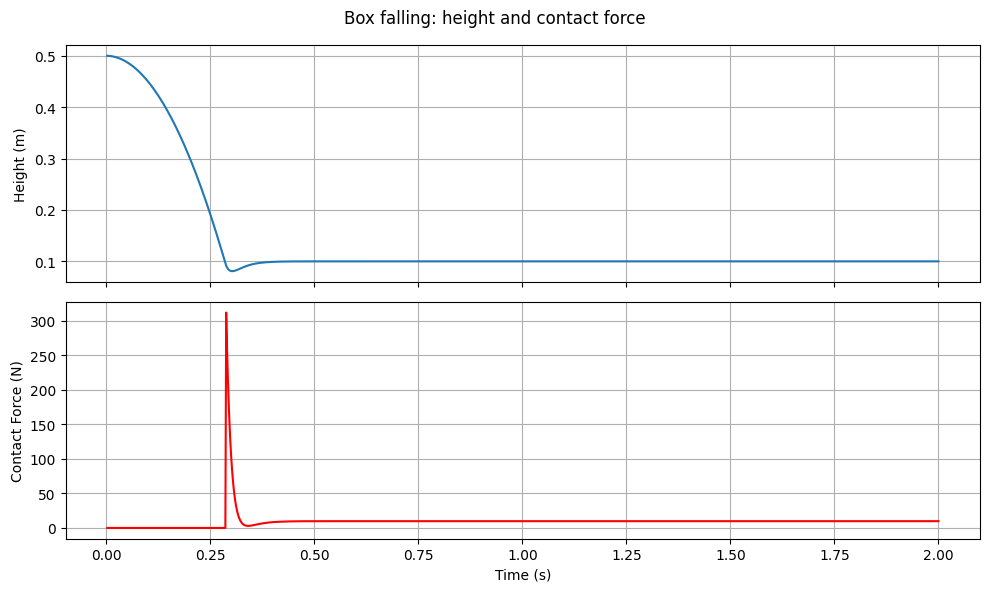

In [3]:
xml = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom name="floor" type="plane" size="2 2 0.1"/>
    <body name="box" pos="0 0 0.5">
      <joint type="free"/>
      <geom name="box_geom" type="box" size="0.1 0.1 0.1" mass="1" rgba="1 0 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# Simulate until contact
contact_times, contact_forces, heights = [], [], []
while data.time < 2.0:
    mujoco.mj_step(model, data)
    heights.append(data.qpos[2])

    # Read contact forces
    total_force = 0.0
    for i in range(data.ncon):
        force = np.zeros(6)
        mujoco.mj_contactForce(model, data, i, force)
        total_force += np.linalg.norm(force[:3])  # normal + friction

    contact_times.append(data.time)
    contact_forces.append(total_force)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(contact_times, heights); ax1.set_ylabel('Height (m)'); ax1.grid(True)
ax2.plot(contact_times, contact_forces, color='red'); ax2.set_ylabel('Contact Force (N)')
ax2.set_xlabel('Time (s)'); ax2.grid(True)
plt.suptitle('Box falling: height and contact force'); plt.tight_layout(); plt.show()

## Contact Parameters

Control contact behavior with `solref` (stiffness/damping) and `friction`:

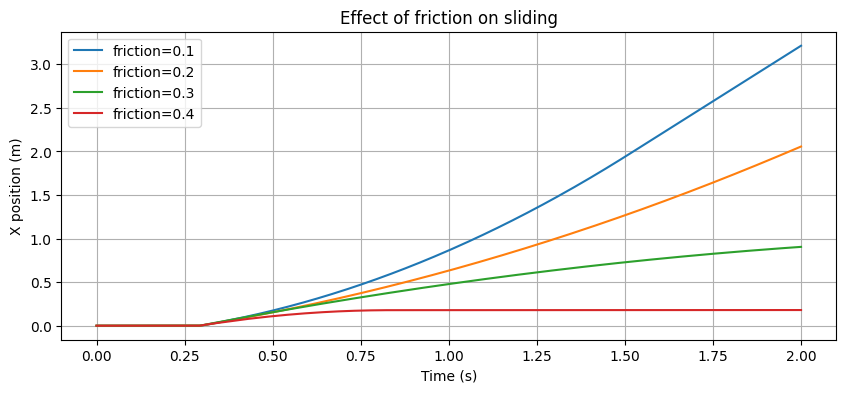

In [6]:
# Compare different friction values
xml_template = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom name="ramp" type="box" size="2 0.5 0.02" euler="0 15 0" pos="0 0 0.5" friction="{friction} 0.005 0.001"/>
    <body pos="0 0 1">
      <joint type="free"/>
      <geom type="box" size="0.05 0.05 0.05" mass="1" rgba="1 0 0 1" friction="{friction} 0.005 0.001"/>
    </body>
  </worldbody>
</mujoco>
"""

plt.figure(figsize=(10, 4))
for friction in [0.1, 0.2, 0.3, 0.4]:
    m = mujoco.MjModel.from_xml_string(xml_template.format(friction=friction))
    d = mujoco.MjData(m)
    positions = []
    while d.time < 2.0:
        mujoco.mj_step(m, d)
        positions.append(d.qpos[0])  # x position
    plt.plot(np.linspace(0, 2, len(positions)), positions, label=f'friction={friction}')

plt.xlabel('Time (s)'); plt.ylabel('X position (m)')
plt.title('Effect of friction on sliding'); plt.legend(); plt.grid(True); plt.show()

## Collision Filtering

Use `contype` and `conaffinity` to control which geoms collide:

In [7]:
xml_filter = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom type="plane" size="2 2 0.1"/>

    <!-- This box WILL collide with floor (default contype=1, conaffinity=1) -->
    <body pos="-0.3 0 1">
      <joint type="free"/>
      <geom type="sphere" size="0.1" rgba="1 0 0 1"/>
    </body>

    <!-- This box will NOT collide (contype=2 doesn't match floor's conaffinity=1) -->
    <body pos="0.3 0 1">
      <joint type="free"/>
      <geom type="sphere" size="0.1" rgba="0 0 1 1" contype="2" conaffinity="2"/>
    </body>
  </worldbody>
</mujoco>
"""

model_f = mujoco.MjModel.from_xml_string(xml_filter)
data_f = mujoco.MjData(model_f)
renderer = mujoco.Renderer(model_f, height=300, width=400)

frames = []
while data_f.time < 2.0:
    mujoco.mj_step(model_f, data_f)
    if len(frames) < data_f.time * 30:
        renderer.update_scene(data_f)
        frames.append(renderer.render().copy())

renderer.close()
media.show_video(frames, fps=30)

This browser does not support the video tag.


The red sphere collides with the floor; the blue sphere passes through it (different collision group).